Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

For the forecasting part, we will use statsmodels

In [2]:
from statsmodels.tsa.arima.model import ARIMA

Create sample Stock_Prices.csv

In [3]:
data = {
    'Date': pd.date_range('2026-01-01', periods=15),
    'Close': [100, 102, 101, 105, 107, 106, 110, 112, 111, 115,
              118, 117, 120, 122, 125],
    'Volume': [1000, 1200, 1100, 1300, 1500, 1400, 1600, 1700,
               1500, 1800, 1900, 1700, 2000, 2100, 2200]
}

df = pd.DataFrame(data)
df.to_csv('Stock_Prices.csv', index=False)

Import and explore dataset

In [4]:
df = pd.read_csv('Stock_Prices.csv')

print(df.head())
print(df.shape)
print(df.info())

         Date  Close  Volume
0  2026-01-01    100    1000
1  2026-01-02    102    1200
2  2026-01-03    101    1100
3  2026-01-04    105    1300
4  2026-01-05    107    1500
(15, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    15 non-null     object
 1   Close   15 non-null     int64 
 2   Volume  15 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 492.0+ bytes
None


Convert Date to datetime

In [5]:
df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)

Date      datetime64[ns]
Close              int64
Volume             int64
dtype: object


Historical Stock Price Trend

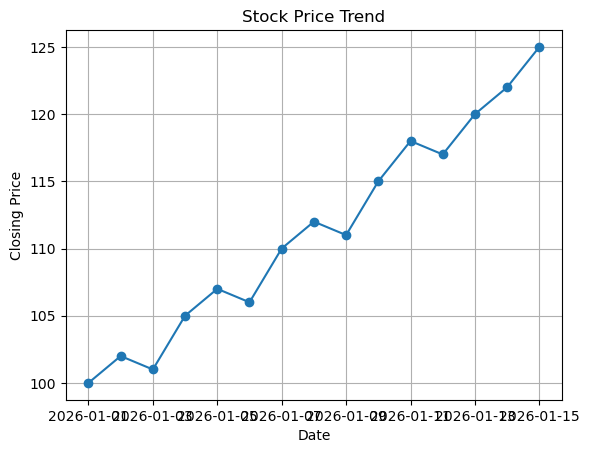

In [6]:
plt.plot(df['Date'], df['Close'], marker='o')

plt.title('Stock Price Trend')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.show()

Moving Average

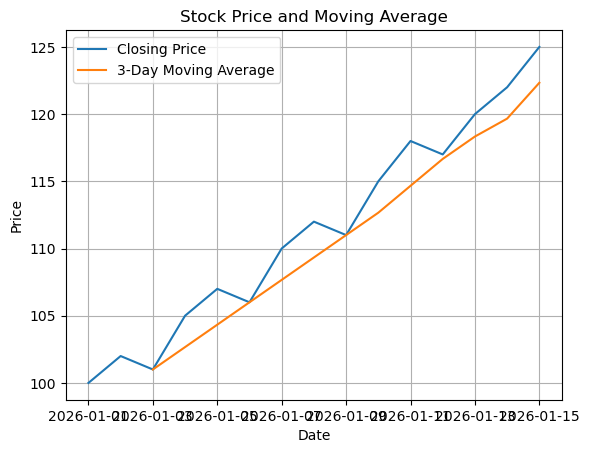

In [7]:
df['Moving_Average'] = df['Close'].rolling(3).mean()

plt.plot(df['Date'], df['Close'], label='Closing Price')
plt.plot(df['Date'], df['Moving_Average'], label='3-Day Moving Average')

plt.title('Stock Price and Moving Average')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid()
plt.show()

Seasonality Analysis

In [8]:
df['Day'] = df['Date'].dt.day_name()

seasonality = df.groupby('Day')['Close'].mean()

print(seasonality)



Day
Friday       106.500000
Monday       112.000000
Saturday     108.000000
Sunday       111.500000
Thursday     112.333333
Tuesday      113.000000
Wednesday    116.000000
Name: Close, dtype: float64


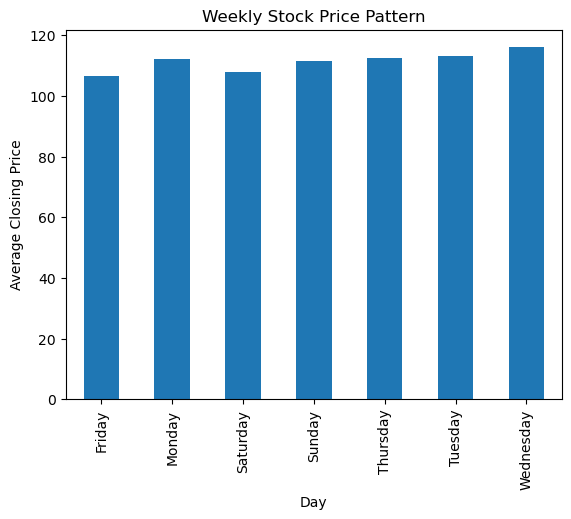

In [9]:
seasonality.plot(kind='bar')

plt.title('Weekly Stock Price Pattern')
plt.xlabel('Day')
plt.ylabel('Average Closing Price')
plt.show()

Correlation with Trading Volume

In [10]:
print(df[['Close', 'Volume']].corr())

           Close    Volume
Close   1.000000  0.982969
Volume  0.982969  1.000000


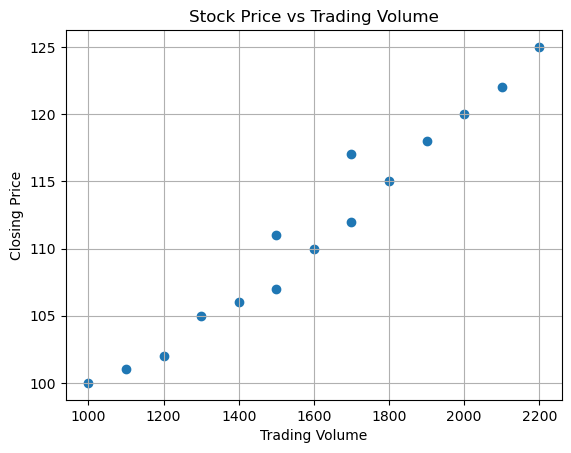

In [11]:
plt.scatter(df['Volume'], df['Close'])

plt.title('Stock Price vs Trading Volume')
plt.xlabel('Trading Volume')
plt.ylabel('Closing Price')
plt.grid()
plt.show()

ARIMA Forecasting

In [12]:
model = ARIMA(df['Close'], order=(1,1,0))
model_fit = model.fit()

forecast = model_fit.forecast(steps=5)

print("Future Stock Prices:")
print(forecast)

Future Stock Prices:
15    125.540692
16    125.638142
17    125.655705
18    125.658871
19    125.659441
Name: predicted_mean, dtype: float64


Plot Forecast

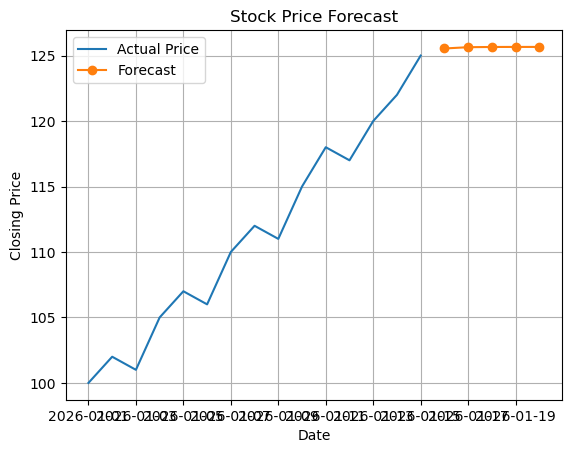

In [13]:
plt.plot(df['Date'], df['Close'], label='Actual Price')

future_dates = pd.date_range(
    start=df['Date'].iloc[-1] + pd.Timedelta(days=1),
    periods=5
)

plt.plot(future_dates, forecast, marker='o', label='Forecast')

plt.title('Stock Price Forecast')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid()
plt.show()